# EN4554 Deep Learning for Vision — Assignment 2: CNNs on CIFAR-10

**Name:** Hathurusingha HAR &nbsp;|&nbsp; **Index:** 220221B  
**GitHub:** https://github.com/achintha-hathurusingha/en4554-a02-cnns

**Use of AI tools.** I used Claude to help write and debug code and to draft explanations. I ran every experiment myself and I have reviewed and understood all code and text.

## 0 · Setup

**How this works**
- One config cell holds every switch. `RUN_TRAINING = False` rebuilds all plots and tables from the saved JSON histories, so a Colab disconnect never forces retraining.
- Results go to Google Drive on Colab and to `./results` elsewhere. The code is device-agnostic: it uses CUDA when available, otherwise the CPU.
- `seed_everything` seeds Python, NumPy and PyTorch (CPU and every GPU), and returns a seeded generator used for mini-batch shuffling.

In [1]:
import os, sys, json, math, time, random, platform, warnings
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"

RUN_TRAINING = True    # False: never train; rebuild every plot/table from saved JSON histories
FORCE_RETRAIN = False  # True: retrain even when a saved history exists
SEED = 0

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/en4554_a2")
    DATA_DIR = Path("/content/data")                 # Colab's local disk is faster than Drive
else:
    ROOT = Path(os.environ.get("A2_ROOT", ".")).resolve()
    DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
CKPT_DIR = RESULTS_DIR / "ckpt"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"                          # mixed precision only on a GPU
DEVICE_NAME = torch.cuda.get_device_name(0) if AMP else (platform.processor() or "CPU")
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step()` before")

print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__}")
print(f"device: {DEVICE_NAME} | AMP: {AMP} | results -> {RESULTS_DIR}")

Python 3.12.3 | torch 2.5.1+cu124 | torchvision 0.20.1+cu124
device: Quadro RTX 5000 | AMP: True | results -> /mnt/minura/minura/en4554-a2/results


In [2]:
def seed_everything(seed=SEED):
    """Seed Python, NumPy and PyTorch (CPU + all GPUs); return a generator for shuffling."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    return torch.Generator().manual_seed(seed)

torch.backends.cudnn.benchmark = True   # fastest conv algorithms; reruns may differ in last digits
seed_everything()

# one colour per method, reused in every figure (Okabe-Ito palette, colour-blind safe)
COLORS = {"train": "#0072B2", "val": "#E69F00",
          "SGD": "#0072B2", "SGD+momentum": "#E69F00", "Adam": "#009E73",
          "sigmoid": "#CC79A7", "ReLU": "#56B4E9",
          "plain": "#999999", "residual": "#0072B2"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})

## 1 · Data: seeded 45k / 5k split and training-split normalisation

**How this works**
- A seeded `randperm` of the 50,000 training images gives the 45k training and 5k validation indices. The same seed always gives the same split, on any machine.
- Per-channel mean and std are computed on the **45k training split only**, so the validation split never leaks into preprocessing: $\hat x_c = (x_c/255 - \mu_c)/\sigma_c$.
- The normalised tensors live on the GPU (45k × 3 × 32 × 32 float32 = 553 MB). `batches()` slices them with a seeded permutation. This shuffles the same way as `DataLoader(shuffle=True, generator=g)` but avoids a CPU data-loading bottleneck.
- The test set is not loaded here. It is used once, in Task 4.

In [3]:
train_set = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
CLASSES = train_set.classes
X_all = torch.from_numpy(train_set.data).permute(0, 3, 1, 2).contiguous()  # uint8 (50000,3,32,32)
y_all = torch.tensor(train_set.targets)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45_000], perm[45_000:]
X_tr_u8, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va_u8, y_va = X_all[va_idx], y_all[va_idx]

x01 = X_tr_u8.float().div_(255)                      # training split only, scaled to [0, 1]
MEAN, STD = x01.mean(dim=(0, 2, 3)), x01.std(dim=(0, 2, 3))
del x01

print(f"train {tuple(X_tr_u8.shape)} | val {tuple(X_va_u8.shape)} | shared indices: "
      f"{len(set(tr_idx.tolist()) & set(va_idx.tolist()))}")
print("channel mean (R, G, B):", MEAN.numpy().round(4), "| channel std:", STD.numpy().round(4))

Files already downloaded and verified


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | shared indices: 0
channel mean (R, G, B): [0.4912 0.482  0.4464] | channel std: [0.2472 0.2436 0.2617]


In [4]:
def normalize(x_u8):
    """uint8 images -> float32 with zero mean / unit std per channel (training-split statistics)."""
    return (x_u8.float().div(255) - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

X_tr, X_va = normalize(X_tr_u8).to(DEVICE), normalize(X_va_u8).to(DEVICE)
y_tr, y_va = y_tr.to(DEVICE), y_va.to(DEVICE)

def batches(X, y, batch_size, shuffle=False, gen=None):
    """Yield (x, y) mini-batches; shuffling uses the seeded CPU generator `gen`."""
    order = torch.randperm(len(X), generator=gen) if shuffle else torch.arange(len(X))
    order = order.to(X.device)
    for i in range(0, len(X), batch_size):
        idx = order[i:i + batch_size]
        yield X[idx], y[idx]

print(f"on {DEVICE}: X_tr {tuple(X_tr.shape)}, X_va {tuple(X_va.shape)}")
print("normalised train split, per-channel mean:", X_tr.mean((0, 2, 3)).cpu().numpy().round(3),
      "| std:", X_tr.std((0, 2, 3)).cpu().numpy().round(3))
print("normalised val split,   per-channel mean:", X_va.mean((0, 2, 3)).cpu().numpy().round(3),
      "| std:", X_va.std((0, 2, 3)).cpu().numpy().round(3))

on cuda: X_tr (45000, 3, 32, 32), X_va (5000, 3, 32, 32)
normalised train split, per-channel mean: [0. 0. 0.] | std: [1. 1. 1.]
normalised val split,   per-channel mean: [0.008 0.007 0.004] | std: [0.995 0.994 0.997]


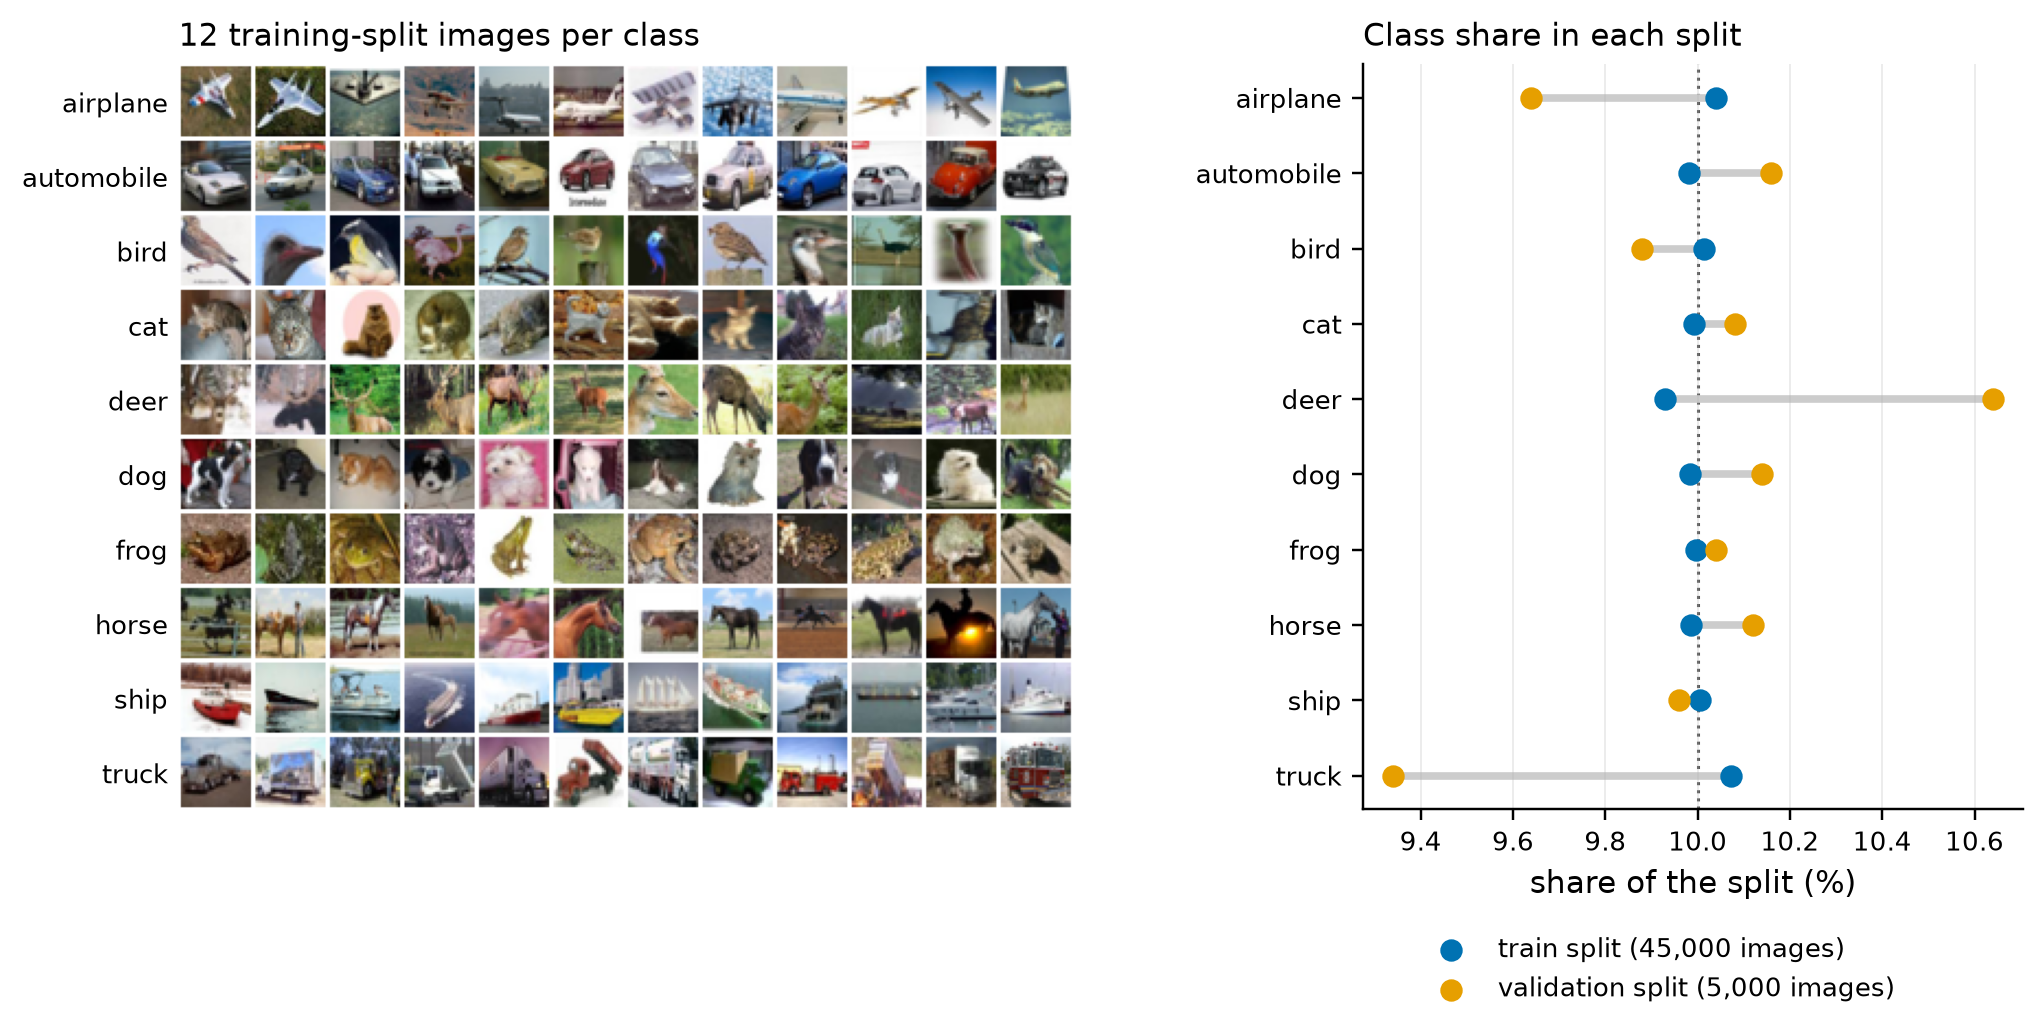

class counts  train: [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]
              val:   [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


In [5]:
fig, (ax_img, ax_bal) = plt.subplots(1, 2, figsize=(11, 4.4),
                                     gridspec_kw={"width_ratios": [1.45, 1], "wspace": 0.32})

# left: a strip of 12 training-split images per class
y_cpu, n_show = y_tr.cpu(), 12
rows = []
for c in range(10):
    idx = (y_cpu == c).nonzero().flatten()[:n_show]
    rows.append(torch.cat([F.pad(X_tr_u8[i], (1, 1, 1, 1), value=255) for i in idx], dim=2))
ax_img.imshow(torch.cat(rows, dim=1).permute(1, 2, 0).numpy())
ax_img.set_yticks([34 * c + 17 for c in range(10)], CLASSES)
ax_img.set_xticks([]); ax_img.grid(False); ax_img.tick_params(length=0)
for s in ax_img.spines.values():
    s.set_visible(False)
ax_img.set_title(f"{n_show} training-split images per class")

# right: share of each class in the two splits (perfect balance = the dotted 10 % line)
share = lambda y: (torch.bincount(y.cpu(), minlength=10) / len(y) * 100).numpy()
s_tr, s_va, ypos = share(y_tr), share(y_va), np.arange(10)
ax_bal.hlines(ypos, np.minimum(s_tr, s_va), np.maximum(s_tr, s_va), color="0.8", lw=2.5, zorder=1)
ax_bal.scatter(s_tr, ypos, color=COLORS["train"], s=40, zorder=3,
               label=f"train split ({len(y_tr):,} images)")
ax_bal.scatter(s_va, ypos, color=COLORS["val"], s=40, zorder=3,
               label=f"validation split ({len(y_va):,} images)")
ax_bal.axvline(10, color="0.35", ls=":", lw=1, zorder=0)
ax_bal.set_yticks(ypos, CLASSES); ax_bal.invert_yaxis(); ax_bal.grid(axis="y", visible=False)
ax_bal.set_xlabel("share of the split (%)")
ax_bal.set_title("Class share in each split")
ax_bal.legend(loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=1)
plt.show()

print("class counts  train:", torch.bincount(y_tr.cpu(), minlength=10).tolist())
print("              val:  ", torch.bincount(y_va.cpu(), minlength=10).tolist())

**Interpretation.** The split is random, not stratified, yet every class stays close to 10 %. Training counts run from 4,468 (deer) to 4,533 (truck), and validation counts from 467 (truck, 9.34 %) to 532 (deer, 10.64 %). The validation shares scatter more only because that split is nine times smaller. A binomial count of 5,000 × 0.1 has standard deviation $\sqrt{5000\cdot0.1\cdot0.9}\approx 21$ images, and the largest validation deviation (33 images) is about 1.6 of those, which is ordinary sampling noise. Class imbalance therefore can't noticeably bias the validation accuracies reported later. After normalising with training statistics (R/G/B mean 0.491/0.482/0.446, std 0.247/0.244/0.262), the training split has mean 0 and std 1 by construction. The validation split lands at means ≤ 0.008 and stds 0.994–0.997, a small offset that is expected because the validation data never entered preprocessing.

## Shared training loop (used by Tasks 2–4)

**How this works**
- `train_one_epoch` runs the forward pass under `torch.autocast` (float16 convolutions and matrix multiplies on the GPU's tensor cores; reductions such as the loss stay in float32).
- `GradScaler` backpropagates $S\cdot L$ instead of $L$ so that small float16 gradients don't underflow to zero. It divides the gradients by $S$ before the update, and skips the step and halves $S$ if any gradient is inf/NaN.
- `evaluate` uses `model.eval()`: batch norm uses its running statistics and dropout is off.
- `run_experiment` trains one configuration and saves its history (losses, accuracies, seconds per epoch) to `results/<name>.json` straight after the run. If the file already exists, it loads it instead of retraining. A loss that becomes inf/NaN stops the run and marks it `diverged`.

In [6]:
def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, batch_size=1000):
    """Mean cross-entropy and accuracy on (X, y) in eval mode."""
    model.eval()
    loss_sum = torch.zeros((), device=X.device)
    correct = torch.zeros((), device=X.device)
    for xb, yb in batches(X, y, batch_size):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(xb)
        loss_sum += F.cross_entropy(logits.float(), yb, reduction="sum")
        correct += (logits.argmax(1) == yb).sum()
    return loss_sum.item() / len(X), correct.item() / len(X)

def train_one_epoch(model, opt, scaler, X, y, gen, batch_size=128, sched=None,
                    augment=None, mix_fn=None, label_smoothing=0.0):
    """One pass over (X, y); returns the mean training loss on the (augmented) batches."""
    model.train()
    loss_sum, n = torch.zeros((), device=X.device), 0
    for xb, yb in batches(X, y, batch_size, shuffle=True, gen=gen):
        if augment is not None:
            xb = augment(xb)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            if mix_fn is None:
                loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
            else:                         # mixup: the loss mixes the two labels like the images
                xb, ya, yb2, lam = mix_fn(xb, yb)
                logits = model(xb)
                loss = lam * F.cross_entropy(logits, ya) + (1 - lam) * F.cross_entropy(logits, yb2)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()     # backprop S*L so fp16 gradients don't underflow
        scaler.step(opt)                  # unscale, then step (skipped if a grad is inf/NaN)
        scaler.update()
        if sched is not None:
            sched.step()                             # schedules here step once per mini-batch
        loss_sum += loss.detach() * len(xb)
        n += len(xb)
    return loss_sum.item() / n

def run_experiment(name, make_model, make_opt, epochs, X=None, y=None, batch_size=128,
                   make_sched=None, augment=None, mix_fn=None, label_smoothing=0.0,
                   eval_train=None, seed=SEED, save_model=False, log_every=None):
    """Train one configuration (or load its saved history) and return the per-epoch history dict."""
    path = RESULTS_DIR / f"{name}.json"
    if path.exists() and not FORCE_RETRAIN:
        h = json.loads(path.read_text())
        print(f"[loaded] {name}: val acc {h['val_acc'][-1]:.2%} after {len(h['val_acc'])} epochs, "
              f"{np.mean(h['epoch_time']):.1f} s/epoch on {h['device']}")
        return h
    if not RUN_TRAINING:
        raise FileNotFoundError(f"{path} is missing and RUN_TRAINING is False")
    X = X_tr if X is None else X
    y = y_tr if y is None else y
    gen = seed_everything(seed)                      # same seed -> same init, same batch order
    model = make_model().to(DEVICE)
    opt = make_opt(model.parameters())
    sched = make_sched(opt, epochs * math.ceil(len(X) / batch_size)) if make_sched else None
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
    h = {"name": name, "params": n_params(model), "device": DEVICE_NAME, "seed": seed,
         "diverged": False,
         "train_loss": [], "val_loss": [], "val_acc": [], "train_acc": [], "epoch_time": []}
    log_every = log_every or max(1, epochs // 5)
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tl = train_one_epoch(model, opt, scaler, X, y, gen, batch_size, sched,
                             augment, mix_fn, label_smoothing)
        if AMP:
            torch.cuda.synchronize()
        h["epoch_time"].append(time.perf_counter() - t0)
        vl, va = evaluate(model, X_va, y_va)
        h["train_loss"].append(tl); h["val_loss"].append(vl); h["val_acc"].append(va)
        if eval_train is not None:                   # e.g. clean (un-augmented) training images
            h["train_acc"].append(evaluate(model, *eval_train)[1])
        diverged = not math.isfinite(tl)
        if ep == 1 or ep % log_every == 0 or diverged:
            print(f"{name} | epoch {ep:>3}/{epochs} | train loss {tl:.4f} | val loss {vl:.4f} | "
                  f"val acc {va:.2%} | {h['epoch_time'][-1]:.1f} s/epoch")
        if diverged:
            h["diverged"] = True
            print(f"{name}: training loss is not finite -> run stopped (diverged)")
            break
    path.write_text(json.dumps(h))
    if save_model:
        torch.save(model.state_dict(), CKPT_DIR / f"{name}.pt")
    return h

def load_history(name):
    return json.loads((RESULTS_DIR / f"{name}.json").read_text())

## Task 1 · Backpropagation by hand (L06)

### (a) Linear, ReLU, sigmoid and softmax cross-entropy with explicit forward/backward

**How this works**
- Each layer caches what its backward pass needs. `backward(g)` receives $g=\partial L/\partial(\text{output})$ and returns $\partial L/\partial(\text{input})$, which is the chain rule applied one layer at a time. No autograd is used.
- Linear, $y = xW + b$ with $x\in\mathbb{R}^{N\times D}$, $W\in\mathbb{R}^{D\times M}$:
  $\quad \dfrac{\partial L}{\partial W} = x^\top g,\qquad \dfrac{\partial L}{\partial b} = \sum_{n} g_n,\qquad \dfrac{\partial L}{\partial x} = g\,W^\top$
- ReLU: $\partial L/\partial x = g\odot\mathbb{1}[x>0]$ (the mask). Sigmoid: $\partial L/\partial x = g\odot\sigma(x)(1-\sigma(x))$.
- Softmax cross-entropy: $p=\mathrm{softmax}(z)$, $L=-\frac1N\sum_n \log p_{n,y_n}$, so $\dfrac{\partial L}{\partial z} = \dfrac{p - Y}{N}$ with $Y$ one-hot. Subtracting $\max_j z_j$ first leaves $p$ unchanged and prevents `exp` overflow.

In [7]:
class Linear:
    """y = x @ W + b, W of shape (d_in, d_out). Caches x for the backward pass."""
    def __init__(self, d_in, d_out, init="kaiming", dtype=torch.float32, device=DEVICE):
        std = math.sqrt(2 / d_in) if init == "kaiming" else math.sqrt(2 / (d_in + d_out))
        self.W = (torch.randn(d_in, d_out, dtype=torch.float64) * std).to(device, dtype)
        self.b = torch.zeros(d_out, dtype=dtype, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, g):              # g = dL/dy, shape (N, d_out)
        self.dW = self.x.T @ g          # dL/dW = x^T g
        self.db = g.sum(0)              # dL/db = sum of g over the batch
        return g @ self.W.T             # dL/dx = g W^T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, g):
        return g * self.mask            # derivative is 1 where x > 0, else 0


class Sigmoid:
    def forward(self, x):
        self.s = 1 / (1 + torch.exp(-x))
        return self.s

    def backward(self, g):
        return g * self.s * (1 - self.s)   # sigma' = sigma (1 - sigma) <= 0.25


class SoftmaxCrossEntropy:
    def forward(self, z, y):
        z = z - z.max(dim=1, keepdim=True).values             # stability shift, p unchanged
        logp = z - z.exp().sum(dim=1, keepdim=True).log()     # log-softmax
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y), device=y.device), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y), device=g.device), self.y] -= 1   # p - one_hot(y)
        return g / len(self.y)                                       # mean over batch -> / N


class MLP:
    """Linear -> act -> ... -> Linear, with a manual backward pass and a plain SGD step."""
    def __init__(self, sizes, act=ReLU, init="kaiming", dtype=torch.float32, device=DEVICE):
        self.layers = []
        for i, (d_in, d_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(d_in, d_out, init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.linears = [layer for layer in self.layers if isinstance(layer, Linear)]
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):                 # chain rule from the loss back to the input
        g = self.criterion.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)

    def sgd_step(self, lr):
        for lin in self.linears:
            lin.W -= lr * lin.dW
            lin.b -= lr * lin.db

    def n_params(self):
        return sum(lin.W.numel() + lin.b.numel() for lin in self.linears)

print("MLP 3072-512-256-10 parameters:", f"{MLP([3072, 512, 256, 10]).n_params():,}")

MLP 3072-512-256-10 parameters: 1,707,274


### (b) Gradient check in float64: against autograd and centred finite differences

**How this works**
- The check runs in float64, so rounding (about $10^{-16}$) can't hide a wrong formula. It uses an MLP 3072‑64‑32‑10 (ReLU) on 16 real training images.
- Reference 1 is **autograd** on an independent copy of the forward pass built from `torch.relu` and `F.cross_entropy`. It checks every gradient entry.
- Reference 2 is **centred differences**, $\dfrac{L(\theta_k+h)-L(\theta_k-h)}{2h}$ with error $O(h^2)$ and $h=10^{-6}$, on 20 random entries per tensor.
- Relative error: $\dfrac{|a-b|}{\max(|a|,|b|,10^{-12})}$. The table reports the largest value per tensor, and `torch.allclose` uses its defaults, `rtol=1e-5` and `atol=1e-8`.

tensor,shape,max rel. error vs autograd,allclose vs autograd,entries checked by FD,max rel. error vs FD,allclose vs FD
W1,3072×64,1.4e-11,True,20,5.1e-08,True
b1,64,1.6e-14,True,20,6.1e-07,True
W2,64×32,6.5e-14,True,20,9.2e-08,True
b2,32,1.1e-14,True,20,6.2e-07,True
W3,32×10,1.6e-14,True,20,1.8e-07,True
b3,10,1.1e-14,True,10,1.2e-06,True


loss: manual 3.061597340901310 | F.cross_entropy 3.061597340901310
torch.allclose(manual, autograd) for every tensor: True
torch.allclose(manual, finite differences) for every tensor: True


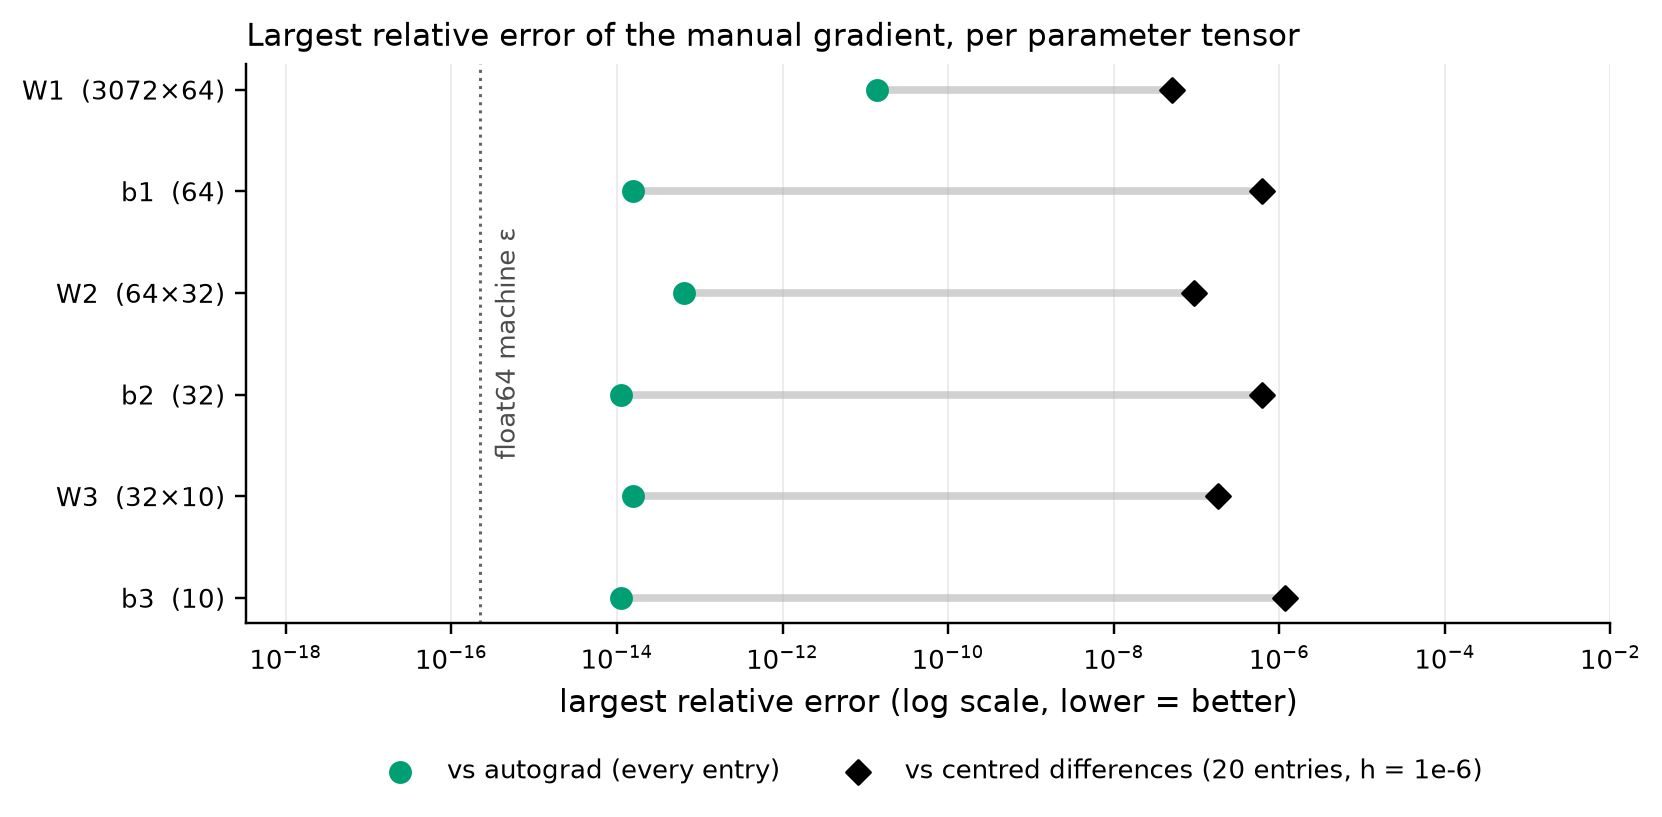

In [8]:
seed_everything()
net = MLP([3072, 64, 32, 10], dtype=torch.float64)
xb, yb = X_tr[:16].flatten(1).double(), y_tr[:16]
loss = net.loss(xb, yb)
net.backward()
tensors, manual = {}, {}
for i, lin in enumerate(net.linears, 1):
    tensors[f"W{i}"], tensors[f"b{i}"] = lin.W, lin.b
    manual[f"W{i}"], manual[f"b{i}"] = lin.dW, lin.db

# reference 1: autograd on an independent functional copy of the network
ref = [t.clone().requires_grad_() for t in tensors.values()]
h = xb
for i in range(0, len(ref), 2):
    h = h @ ref[i] + ref[i + 1]
    if i < len(ref) - 2:
        h = torch.relu(h)
loss_ag = F.cross_entropy(h, yb)
loss_ag.backward()
autograd = {name: t.grad for name, t in zip(tensors, ref)}

def rel_err(a, b):
    return (a - b).abs() / torch.clamp(torch.maximum(a.abs(), b.abs()), min=1e-12)

# reference 2: centred finite differences on K random entries per tensor
H, K = 1e-6, 20
gen = torch.Generator().manual_seed(SEED)
rows = []
for name, theta in tensors.items():
    flat = theta.view(-1)                                  # a view: editing it edits the weights
    idx = torch.randperm(flat.numel(), generator=gen)[:K]
    fd = torch.empty(len(idx), dtype=torch.float64)
    for j, k in enumerate(idx.tolist()):
        old = flat[k].item()
        flat[k] = old + H; l_plus = net.loss(xb, yb).item()
        flat[k] = old - H; l_minus = net.loss(xb, yb).item()
        flat[k] = old
        fd[j] = (l_plus - l_minus) / (2 * H)
    g_man = manual[name].reshape(-1)[idx].cpu()
    rows.append({"tensor": name, "shape": "×".join(map(str, theta.shape)),
                 "max rel. error vs autograd": rel_err(manual[name], autograd[name]).max().item(),
                 "allclose vs autograd": torch.allclose(manual[name], autograd[name]),
                 "entries checked by FD": len(idx),
                 "max rel. error vs FD": rel_err(g_man, fd).max().item(),
                 "allclose vs FD": torch.allclose(g_man, fd)})
gc = pd.DataFrame(rows)
display(gc.style.format({"max rel. error vs autograd": "{:.1e}", "max rel. error vs FD": "{:.1e}"})
          .hide(axis="index"))
print(f"loss: manual {loss.item():.15f} | F.cross_entropy {loss_ag.item():.15f}")
print("torch.allclose(manual, autograd) for every tensor:", bool(gc["allclose vs autograd"].all()))
print("torch.allclose(manual, finite differences) for every tensor:",
      bool(gc["allclose vs FD"].all()))

# figure: largest relative error per tensor on a log axis (exact zeros drawn at the floor)
floor = 1e-18
fig, ax = plt.subplots(figsize=(8, 3.3))
ypos = np.arange(len(gc))
ag = np.maximum(gc["max rel. error vs autograd"].to_numpy(), floor)
fdv = np.maximum(gc["max rel. error vs FD"].to_numpy(), floor)
ax.hlines(ypos, np.minimum(ag, fdv), np.maximum(ag, fdv), color="0.82", lw=2.5, zorder=1)
ax.scatter(ag, ypos, color="#009E73", s=42, zorder=3, label="vs autograd (every entry)")
ax.scatter(fdv, ypos, color="black", marker="D", s=30, zorder=3,
           label=f"vs centred differences ({K} entries, h = 1e-6)")
ax.axvline(np.finfo(np.float64).eps, color="0.4", ls=":", lw=1)
eps64 = np.finfo(np.float64).eps
ax.text(eps64 * 1.5, (len(gc) - 1) / 2, "float64 machine ε", rotation=90, va="center",
        fontsize=8.5, color="0.3")
ax.set_xscale("log"); ax.set_xlim(floor / 3, 1e-2)
ax.set_yticks(ypos, [f"{t}  ({s})" for t, s in zip(gc["tensor"], gc["shape"])]); ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("largest relative error (log scale, lower = better)")
ax.set_title("Largest relative error of the manual gradient, per parameter tensor")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.show()

**Interpretation.** All six gradient tensors pass both checks. `torch.allclose` is True against autograd and against centred differences, and the manual and `F.cross_entropy` losses agree to all 15 printed decimals (3.061597340901310). Against autograd the largest relative errors are $1.1\times10^{-14}$ to $1.4\times10^{-11}$, which is rounding-level agreement: the two implementations differ only in the order of floating-point operations. That confirms $x^\top g$, $\sum g$, $gW^\top$, the ReLU mask and $(p-Y)/N$. The finite-difference errors are larger ($5.1\times10^{-8}$ to $1.2\times10^{-6}$), and that comes from the reference itself. Subtracting two losses of size ≈ 3.06 loses about $\varepsilon L/h\approx7\times10^{-10}$ in absolute terms, on top of the $O(h^2)$ truncation, and this is large relative to the smallest gradient entries. A real bug, such as a missing $1/N$, would give relative errors near 1.